In [ ]:
from pathlib import Path
import os, sys
_root = next((p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents] if (p / "REPOSITORY_PROVENANCE.json").is_file()), None)
if _root is None:
    raise RuntimeError("Start Jupyter inside this experiment repository.")
os.chdir(_root)
sys.path.insert(0, str(_root))


# Ten-qubit majority Pauli-gradient spectrum during CartPole-v1/200 training

This notebook tests whether the higher-weight Pauli sectors of the **valid,
full deterministic nine-measured-bit majority policy** become more important during
training.  The trained policy is never spectrally truncated.

The circuit, initialization, state encoding, optimizer, five-episode batching,
and 500-episode analytic-gradient protocol match the ten-qubit connected cubic
graph, L=1 experiment in `test_policy_training_efficiency.ipynb` and
`majority_local_sector_ablation.ipynb`.

## Contents

1. [Protocol and exact decomposition](#protocol)
2. [Exact QASP circuit mirror](#circuit)
3. [Gradient-attribution validation](#validation)
4. [Ten-seed production run](#production)
5. [Aggregation and statistics](#aggregation)
6. [Publication figure](#figure)
7. [Reproducibility manifest](#manifest)

In [1]:
import copy
import hashlib
import importlib.metadata as importlib_metadata
import itertools
import json
import math
import os
import platform
import random
import sys
import time
import warnings
from pathlib import Path

os.environ.setdefault("OMP_NUM_THREADS", "1")
os.environ.setdefault("MKL_NUM_THREADS", "1")

import gymnasium as gym
import joblib
import matplotlib as mpl
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
import pennylane as qml
import scipy
import torch
from IPython.display import display
from torch.distributions import Categorical

import qasp
from qasp.rl.model import create_model

ROOT = Path(".")
RESULTS_DIR = ROOT / "tests" / "results" / "majority_gradient_spectrum_during_training_10q"
RUNS_DIR = RESULTS_DIR / "runs"
RAW_DIR = RESULTS_DIR / "raw"
FIGURES_DIR = RESULTS_DIR / "figures"
for directory in (RESULTS_DIR, RUNS_DIR, RAW_DIR, FIGURES_DIR):
    directory.mkdir(parents=True, exist_ok=True)

SEEDS = (3, 7, 11, 23, 37, 41, 43, 47, 53, 59)
N_EPISODES = 500
MAX_STEPS = 200
BATCH_EPISODES = 5
N_UPDATES = N_EPISODES // BATCH_EPISODES
BIN_WIDTH = 50
SOLVED_THRESHOLD = 195.0
N_JOBS = 2
EPS = 1e-10
PROTOCOL_VERSION = "source_action_rng_reset_after_model_init_v2_exact_sector_vjp"

TRAINING = {
    "gamma": 0.99,
    "lr": 0.03,
    "optimizer": "Adam(amsgrad=True)",
    "batch_episodes": BATCH_EPISODES,
    "normalize_mode": "clip",
    "normalize_returns": True,
    "baseline_type": "ema",
    "baseline_momentum": 0.05,
    "entropy_coef": 0.005,
    "max_grad_norm": 1.0,
}

EXPANDER_EDGES = [
    (0, 5), (0, 6), (0, 7), (1, 2), (1, 4),
    (1, 7), (2, 6), (2, 8), (3, 4), (3, 7),
    (3, 9), (4, 9), (5, 6), (5, 8), (8, 9),
]

SPEC = {
    "label": "10-qubit connected cubic graph, L=1 (9 measured)",
    "n_qubits": 10,
    "n_layers": 1,
    "edges": EXPANDER_EDGES,
    "measurement_wires": list(range(9)),
    "initializer": "uniform",
    "expected_quantum_parameters": 65,
    "accepted_networkx_seed": 1039606416,
}
ODD_WEIGHTS = tuple(range(1, len(SPEC["measurement_wires"]) + 1, 2))
graph = nx.Graph()
graph.add_nodes_from(range(SPEC["n_qubits"]))
graph.add_edges_from(SPEC["edges"])
assert nx.is_connected(graph)
assert all(degree == 3 for _, degree in graph.degree())
assert SPEC["measurement_wires"] == list(range(9)) and 9 not in SPEC["measurement_wires"]

mpl.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": 300,
    "font.size": 9,
    "axes.titlesize": 10,
    "axes.labelsize": 9,
    "legend.fontsize": 8,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})

print("QASP:", getattr(qasp, "__version__", importlib_metadata.version("qasp")))
print("PennyLane:", qml.__version__, "Torch:", torch.__version__)
print("Seeds:", SEEDS)
print("Results:", RESULTS_DIR)

QASP: 0.1.0
PennyLane: 0.42.2 Torch: 2.7.0
Seeds: (3, 7, 11, 23, 37, 41, 43, 47, 53, 59)
Results: ./tests/results/majority_gradient_spectrum_during_training_10q


<a id="protocol"></a>
## Protocol and exact decomposition

For the nine measured qubits of the ten-qubit circuit, the deterministic
majority observable is

\[
M_9=\frac{35}{128}\sum_{|S|=1}Z_S
-\frac{5}{128}\sum_{|S|=3}Z_S
+\frac{3}{128}\sum_{|S|=5}Z_S
-\frac{5}{128}\sum_{|S|=7}Z_S
+\frac{35}{128}Z_1\cdots Z_9,
\qquad
\Pi_0=\frac{I+M_9}{2},\quad \Pi_1=\frac{I-M_9}{2}.
\]

Even weights vanish exactly.  Qubit 10 remains coupled through the cubic graph
but is traced out by the decoder.  At each five-episode update, the notebook
first computes the ordinary full-policy loss, including the selected-action
log-probability, normalized advantage, and entropy regularizer.  If
\(c_t=\partial L/\partial M_9(x_t)\), the contribution of string \(S\) is

\[
g_S=\nabla_\theta\sum_t c_t\,\widehat M_S(x_t),
\]

with \(c_t\) detached only after it has been obtained from the full loss.
Consequently \(g=\sum_S g_S\) by the chain rule.  The same global gradient-clip
factor is then applied to every string vector, so their sum equals the gradient
actually passed to Adam.

The source QASP trainer normally freezes optimization once its CartPole solve
criterion is met.  For this diagnostic, optimization deliberately continues
through all 100 updates so that late zero gradients cannot be mistaken for
sector disappearance.  The episode at which the source rule *would* first
freeze is retained in every relevant table.

In [2]:
def build_pauli_table(n=9):
    bitstrings = np.asarray(list(itertools.product((0, 1), repeat=n)), dtype=int)
    majority = np.where(bitstrings.sum(axis=1) <= n // 2, 1.0, -1.0)
    rows = []
    string_index = 0
    for weight in ODD_WEIGHTS:
        for support in itertools.combinations(range(n), weight):
            character = (-1.0) ** bitstrings[:, support].sum(axis=1)
            coefficient = float(np.mean(majority * character))
            label = "".join("Z" if wire in support else "I" for wire in range(n))
            rows.append({
                "string_index": string_index,
                "weight": weight,
                "support_zero_based": " ".join(map(str, support)),
                "pauli_string": label,
                "coefficient": coefficient,
            })
            string_index += 1
    table = pd.DataFrame(rows)
    assert len(table) == 2 ** (n - 1)
    assert table.groupby("weight").size().to_dict() == {
        weight: math.comb(n, weight) for weight in ODD_WEIGHTS
    }
    expected = {1: 35/128, 3: -5/128, 5: 3/128, 7: -5/128, 9: 35/128}
    for weight, coefficient in expected.items():
        np.testing.assert_allclose(
            table.loc[table.weight == weight, "coefficient"], coefficient, atol=1e-12
        )
    return table


PAULI_TABLE = build_pauli_table()
PAULI_TABLE.to_csv(RESULTS_DIR / "majority_pauli_decomposition.csv", index=False)
display(PAULI_TABLE)

,string_index,weight,support_zero_based,pauli_string,coefficient
0,0,1,0,ZIIIIIIII,0.273438
1,1,1,1,IZIIIIIII,0.273438
2,2,1,2,IIZIIIIII,0.273438
3,3,1,3,IIIZIIIII,0.273438
4,4,1,4,IIIIZIIII,0.273438
...,...,...,...,...,...
251,251,7,1 2 3 5 6 7 8,IZZZIZZZZ,-0.039062
252,252,7,1 2 4 5 6 7 8,IZZIZZZZZ,-0.039062
253,253,7,1 3 4 5 6 7 8,IZIZZZZZZ,-0.039062
254,254,7,2 3 4 5 6 7 8,IIZZZZZZZ,-0.039062


<a id="circuit"></a>
## Exact QASP circuit mirror

The live QASP factory supplies the authoritative initialized tensors.  The
analytic Torch statevector below implements the same state-conditioned repeated
IQP-like program in a batch-friendly form.  It is validated against the QASP
model before production.  Only quantum-policy parameters are present:
60 state-encoding scales and 30 circuit angles.

In [3]:
def qasp_initial_state(seed):
    config = {
        "ansatz": "IQPAnsatz",
        "ansatz_config": {
            "n_layers": SPEC["n_layers"],
            "imprimitive_pattern": copy.deepcopy(SPEC["edges"]),
            "reuploading": True,
            "include_single_qubit": True,
        },
        "feature_map": "NeuralEmbedding",
        "feature_map_config": {"features": 4, "rotations": "Z"},
        "n_actions": 2,
        "init": SPEC["initializer"],
        "device": "lightning.qubit",
        "diff_method": "adjoint",
        "shots": None,
        "softmax_activation": False,
        "output_scaling": None,
        "torchrl": False,
        "measurement_qubits": list(SPEC["measurement_wires"]),
        "parity_cnot_decomposition": False,
        "policy": "parity-like",
        "training_method": "expectation",
        "enable_mpi": False,
    }
    torch.manual_seed(int(seed))
    np.random.seed(int(seed))
    model = create_model("PQCBorn", config, n_qubits=SPEC["n_qubits"])
    state = {key: value.detach().cpu().clone()
             for key, value in model.qlayer.state_dict().items()}
    del model
    return state


def trainable_hash(model):
    payload = b"".join(
        value.detach().cpu().contiguous().numpy().tobytes()
        for name, value in sorted(model.named_parameters()) if value.requires_grad
    )
    return hashlib.sha256(payload).hexdigest()


class ExactMajorityIQP(torch.nn.Module):
    def __init__(self, seed):
        super().__init__()
        initial = qasp_initial_state(seed)
        self.input_scaling_params = torch.nn.Parameter(
            initial["input_scaling_params"].clone()
        )
        self.params = torch.nn.Parameter(initial["params"].clone())

        n = SPEC["n_qubits"]
        dimension = 1 << n
        basis = torch.arange(dimension, dtype=torch.long)
        shifts = torch.arange(n - 1, -1, -1, dtype=torch.long)
        bits = ((basis[:, None] >> shifts[None, :]) & 1).to(torch.float32)
        z_signs = (1.0 - 2.0 * bits).T
        self.register_buffer("z_signs", z_signs)
        self.register_buffer("zz_signs", torch.stack([
            z_signs[left] * z_signs[right] for left, right in SPEC["edges"]
        ]))

        string_signs = []
        for row in PAULI_TABLE.itertuples(index=False):
            support = [int(item) for item in row.support_zero_based.split()]
            string_signs.append(torch.prod(z_signs[support], dim=0))
        self.register_buffer("string_signs", torch.stack(string_signs))
        self.register_buffer(
            "string_coefficients",
            torch.tensor(PAULI_TABLE.coefficient.to_numpy(), dtype=torch.float32),
        )

        majority_diag = (bits[:, SPEC["measurement_wires"]].sum(dim=1) <= len(SPEC["measurement_wires"]) // 2).to(torch.float32)
        self.register_buffer("majority_pi0_diagonal", majority_diag)

    @staticmethod
    def _hadamards(state):
        result = state
        width = 1
        dimension = state.shape[-1]
        while width < dimension:
            blocks = result.reshape(*result.shape[:-1], -1, 2, width)
            left = blocks[..., 0, :]
            right = blocks[..., 1, :]
            result = torch.stack((left + right, left - right), dim=-2)
            result = result.reshape(*state.shape[:-1], dimension) / math.sqrt(2.0)
            width *= 2
        return result

    def exact_basis_probs(self, states):
        states = torch.as_tensor(states, dtype=torch.float32)
        n = SPEC["n_qubits"]
        layers = SPEC["n_layers"]
        block = n + len(SPEC["edges"])
        weights = self.input_scaling_params.reshape(layers, n, 4)
        dimension = 1 << n
        state = torch.ones(*states.shape[:-1], dimension, dtype=torch.complex64)
        state = state / math.sqrt(dimension)
        for layer in range(layers):
            encoded = torch.einsum("...f,qf->...q", states, weights[layer])
            start = layer * block
            phase = self.params[start:start+n]
            entangling = self.params[start+n:start+block]
            angle = torch.einsum("...q,qd->...d", encoded, self.z_signs)
            angle = angle + torch.einsum("q,qd->d", phase, self.z_signs)
            angle = angle + torch.einsum("e,ed->d", entangling, self.zz_signs)
            state = state * torch.exp(-0.5j * angle)
            state = self._hadamards(state)
        return state.abs().square().real

    def majority_terms(self, states):
        basis = self.exact_basis_probs(states)
        expectations = torch.einsum("...d,sd->...s", basis, self.string_signs)
        return expectations * self.string_coefficients

    def probabilities_and_terms(self, states):
        terms = self.majority_terms(states)
        observable = terms.sum(dim=-1)
        p0 = 0.5 * (1.0 + observable)
        probs = torch.stack((p0, 1.0 - p0), dim=-1)
        probs = probs.clamp_min(0.0)
        probs = probs / probs.sum(dim=-1, keepdim=True).clamp_min(1e-12)
        return probs, terms

    def projector_probabilities(self, states):
        basis = self.exact_basis_probs(states)
        p0 = torch.einsum("...d,d->...", basis, self.majority_pi0_diagonal)
        return torch.stack((p0, 1.0 - p0), dim=-1)


def parameter_layout(model):
    rows = []
    offset = 0
    for name, parameter in model.named_parameters():
        for local_index in range(parameter.numel()):
            rows.append({
                "parameter_index": offset + local_index,
                "parameter_name": name,
                "parameter_local_index": local_index,
            })
        offset += parameter.numel()
    table = pd.DataFrame(rows)
    assert len(table) == SPEC["expected_quantum_parameters"]
    return table


probe = ExactMajorityIQP(SEEDS[0])
PARAMETER_LAYOUT = parameter_layout(probe)
PARAMETER_LAYOUT.to_csv(RESULTS_DIR / "parameter_layout.csv", index=False)
print("Trainable parameters:", sum(p.numel() for p in probe.parameters()))
print("Initial hash:", trainable_hash(probe))

Trainable parameters: 65
Initial hash: a69b2c88f656d2fcc395c1b2a372c2d663500d5791cab983f078ed591496ad40


<a id="validation"></a>
## Gradient-attribution validation

This cell checks the exact majority identity against the diagonal projector,
compares both gradients, and validates the 256-string batched VJP against the
ordinary full loss gradient.  The reported reconstruction tolerance is for the
float32/complex64 training precision used by the source experiment.

In [4]:
def flatten_grads(grads):
    return torch.cat([gradient.reshape(-1) for gradient in grads])


def string_gradient_attribution(model, states, actions, advantages):
    parameters = tuple(model.parameters())
    terms = model.majority_terms(states)
    observable = terms.sum(dim=-1)
    p0 = 0.5 * (1.0 + observable)
    probabilities = torch.stack((p0, 1.0 - p0), dim=-1)
    probabilities = probabilities.clamp_min(0.0)
    probabilities = probabilities / probabilities.sum(
        dim=-1, keepdim=True
    ).clamp_min(1e-12)
    chosen = probabilities.gather(1, actions[:, None]).squeeze(1).clamp_min(1e-10)
    logp = torch.log(chosen)
    entropy = -(probabilities.clamp_min(1e-10) *
                torch.log(probabilities.clamp_min(1e-10))).sum(dim=1)
    loss = -(advantages.detach() * logp).mean()
    loss = loss - TRAINING["entropy_coef"] * entropy.mean()

    dloss_dobservable = torch.autograd.grad(
        loss, observable, retain_graph=True
    )[0]
    full_grads = torch.autograd.grad(loss, parameters, retain_graph=True)
    full_vector = flatten_grads(full_grads)

    string_objectives = (dloss_dobservable.detach()[:, None] * terms).sum(dim=0)
    weights_array = PAULI_TABLE.weight.to_numpy()
    sector_objectives = torch.stack([
        string_objectives[torch.tensor(weights_array == weight)].sum()
        for weight in ODD_WEIGHTS
    ])
    identity = torch.eye(len(ODD_WEIGHTS), dtype=sector_objectives.dtype)
    sector_grads = torch.autograd.grad(
        sector_objectives,
        parameters,
        grad_outputs=identity,
        is_grads_batched=True,
    )
    sector_vectors = torch.cat(
        [gradient.reshape(len(ODD_WEIGHTS), -1) for gradient in sector_grads], dim=1
    )
    return {
        "loss": loss,
        "probabilities": probabilities,
        "entropy": entropy,
        "full_grads": full_grads,
        "full_vector": full_vector,
        "sector_vectors": sector_vectors,
        "terms": terms,
    }


torch.manual_seed(20260929)
validation_model = ExactMajorityIQP(SEEDS[0])
validation_states = torch.randn(64, 4) * 0.25
validation_actions = torch.randint(0, 2, (64,))
validation_advantages = torch.randn(64)

decomp_probs, _ = validation_model.probabilities_and_terms(validation_states)
projector_probs = validation_model.projector_probabilities(validation_states)
torch.testing.assert_close(decomp_probs, projector_probs, atol=2e-6, rtol=2e-6)

attribution = string_gradient_attribution(
    validation_model, validation_states, validation_actions, validation_advantages
)
relative_error = torch.linalg.vector_norm(
    attribution["full_vector"] - attribution["sector_vectors"].sum(dim=0)
) / torch.linalg.vector_norm(attribution["full_vector"]).clamp_min(EPS)

# Independent projector-gradient comparison.
projector_model = ExactMajorityIQP(SEEDS[0])
projector_probs = projector_model.projector_probabilities(validation_states)
chosen = projector_probs.gather(1, validation_actions[:, None]).squeeze(1).clamp_min(1e-10)
entropy = -(projector_probs.clamp_min(1e-10) *
            torch.log(projector_probs.clamp_min(1e-10))).sum(dim=1)
projector_loss = -(validation_advantages * torch.log(chosen)).mean()
projector_loss = projector_loss - TRAINING["entropy_coef"] * entropy.mean()
projector_grads = torch.autograd.grad(projector_loss, tuple(projector_model.parameters()))
projector_vector = flatten_grads(projector_grads)
torch.testing.assert_close(
    attribution["full_vector"], projector_vector, atol=3e-5, rtol=3e-4
)

assert float(relative_error) < 2e-5
print("Probability max abs error:", float((decomp_probs - projector_probs).abs().max()))
print("Gradient reconstruction relative error:", float(relative_error))
print("Exact sector VJPs:", attribution["sector_vectors"].shape)

Probability max abs error: 2.384185791015625e-07
Gradient reconstruction relative error: 3.691338008593448e-07
Exact sector VJPs: torch.Size([5, 65])


<a id="production"></a>
## Ten-seed production run

Every seed writes an independent checkpoint directory.  A completed seed is
loaded rather than rerun.  Interaction probabilities are retained per step;
the differentiable batch is recomputed once at each update, which is exactly
equivalent to retaining 5 episodes of autograd graphs and is substantially more
memory efficient.

In [5]:
def preprocess_cartpole(state):
    scale = torch.tensor([2.4, 3.0, 0.2095, 3.5], dtype=torch.float32)
    return torch.clamp(torch.as_tensor(state, dtype=torch.float32) / scale, -3.0, 3.0)


def discounted_returns(rewards, gamma):
    running = 0.0
    values = []
    for reward in reversed(rewards):
        running = float(reward) + gamma * running
        values.insert(0, running)
    return torch.tensor(values, dtype=torch.float32)


def write_vector_parquet(path, vectors, update_numbers, item_table, item_key):
    # vectors: [updates, items, parameters]
    updates, items, parameters = vectors.shape
    frame = pd.DataFrame({
        "update": np.repeat(update_numbers, items * parameters),
        item_key: np.tile(np.repeat(np.arange(items), parameters), updates),
        "parameter_index": np.tile(np.arange(parameters), updates * items),
        "gradient_component": vectors.reshape(-1).astype(np.float32),
    })
    frame = frame.merge(item_table, on=item_key, how="left", validate="many_to_one")
    frame = frame.merge(PARAMETER_LAYOUT, on="parameter_index", how="left",
                        validate="many_to_one")
    frame.to_parquet(path, index=False, compression="zstd")


def seed_complete(seed):
    seed_dir = RUNS_DIR / f"seed_{seed}"
    metadata_path = seed_dir / "metadata.json"
    required = [
        "episode_metrics.csv", "update_metrics.csv", "sector_metrics.csv",
        "step_metrics.parquet", "sector_gradient_vectors.parquet", "final_state.pt",
    ]
    if not metadata_path.exists() or not all((seed_dir / name).exists() for name in required):
        return False
    metadata = json.loads(metadata_path.read_text())
    return (
        metadata.get("completed") is True
        and metadata.get("n_updates") == N_UPDATES
        and metadata.get("protocol_version") == PROTOCOL_VERSION
    )


def run_seed(seed):
    seed = int(seed)
    seed_dir = RUNS_DIR / f"seed_{seed}"
    seed_dir.mkdir(parents=True, exist_ok=True)
    if seed_complete(seed):
        return json.loads((seed_dir / "metadata.json").read_text())

    start_time = time.perf_counter()
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    model = ExactMajorityIQP(seed)
    initial_hash = trainable_hash(model)
    optimizer = torch.optim.Adam(model.parameters(), lr=TRAINING["lr"], amsgrad=True)
    env = gym.make("CartPole-v1")

    # Match the source ablation exactly: model construction consumes random
    # draws, then the action-sampling streams are reset before training.
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    env.reset(seed=seed)
    env.action_space.seed(seed)

    baseline_value = 0.0
    baseline_initialized = False
    batch_states = []
    batch_actions = []
    batch_advantages = []
    batch_episode_ids = []
    episode_rows = []
    step_rows = []
    update_rows = []
    sector_rows = []
    string_rows = []
    string_vector_blocks = []
    sector_vector_blocks = []
    update_numbers = []
    returns_history = []
    source_freeze_episode = None

    parameter_shapes = [tuple(parameter.shape) for parameter in model.parameters()]
    weights_array = PAULI_TABLE.weight.to_numpy()

    for episode in range(1, N_EPISODES + 1):
        state, _ = env.reset()
        states = []
        actions = []
        rewards = []
        episode_step_indices = []

        for step in range(1, MAX_STEPS + 1):
            processed = preprocess_cartpole(state)
            with torch.no_grad():
                probabilities, _ = model.probabilities_and_terms(processed)
                distribution = Categorical(probs=probabilities)
                action = distribution.sample()
                entropy = distribution.entropy()
            next_state, reward, terminated, truncated, _ = env.step(int(action.item()))
            chosen_probability = float(probabilities[action].item())
            step_rows.append((
                seed, episode, step, int(action.item()),
                float(probabilities[0].item()), float(probabilities[1].item()),
                chosen_probability, float(entropy.item()),
            ))
            episode_step_indices.append(len(step_rows) - 1)
            states.append(processed)
            actions.append(int(action.item()))
            rewards.append(float(reward))
            state = next_state
            if terminated or truncated:
                break

        episode_return = float(sum(rewards))
        returns_history.append(episode_return)
        discounted = discounted_returns(rewards, TRAINING["gamma"])
        baseline_before = baseline_value
        advantages = discounted - baseline_before
        target = float(discounted.mean().item())
        if not baseline_initialized:
            baseline_value = target
            baseline_initialized = True
        else:
            momentum = TRAINING["baseline_momentum"]
            baseline_value = (1.0 - momentum) * baseline_value + momentum * target

        batch_states.extend(states)
        batch_actions.extend(actions)
        batch_advantages.append(advantages)
        batch_episode_ids.extend([episode] * len(states))
        episode_rows.append({
            "seed": seed,
            "episode": episode,
            "return": episode_return,
            "trajectory_length": len(rewards),
            "mean_action_probability": float(np.mean([
                step_rows[index][6] for index in episode_step_indices
            ])),
            "mean_entropy": float(np.mean([
                step_rows[index][7] for index in episode_step_indices
            ])),
            "baseline_before": baseline_before,
            "baseline_after": baseline_value,
        })

        if episode % BATCH_EPISODES != 0:
            continue

        update = episode // BATCH_EPISODES
        states_tensor = torch.stack(batch_states)
        actions_tensor = torch.tensor(batch_actions, dtype=torch.long)
        advantage_tensor = torch.cat(batch_advantages)
        if TRAINING["normalize_returns"] and len(advantage_tensor) > 1:
            advantage_tensor = (
                advantage_tensor - advantage_tensor.mean()
            ) / (advantage_tensor.std() + 1e-8)

        optimizer.zero_grad(set_to_none=True)
        attribution = string_gradient_attribution(
            model, states_tensor, actions_tensor, advantage_tensor
        )
        full_pre = attribution["full_vector"].detach()
        sectors_pre = attribution["sector_vectors"].detach()
        reconstruction_pre = torch.linalg.vector_norm(
            full_pre - sectors_pre.sum(dim=0)
        ) / torch.linalg.vector_norm(full_pre).clamp_min(EPS)

        # Assign the independently computed full gradient, clip exactly as the
        # source trainer does, and capture the gradient actually passed to Adam.
        for parameter, gradient in zip(model.parameters(), attribution["full_grads"]):
            parameter.grad = gradient.detach().clone()
        preclip_norm_reported = torch.nn.utils.clip_grad_norm_(
            list(model.parameters()), max_norm=TRAINING["max_grad_norm"]
        )
        full_used = torch.cat([parameter.grad.reshape(-1) for parameter in model.parameters()])
        pre_norm = float(torch.linalg.vector_norm(full_pre).item())
        used_norm = float(torch.linalg.vector_norm(full_used).item())
        clip_scale = used_norm / pre_norm if pre_norm > EPS else 1.0
        sector_vectors = sectors_pre * clip_scale

        reconstruction_used = torch.linalg.vector_norm(
            full_used - sector_vectors.sum(dim=0)
        ) / torch.linalg.vector_norm(full_used).clamp_min(EPS)
        sector_norms = torch.linalg.vector_norm(sector_vectors, dim=1)
        norm_denom = sector_norms.sum().clamp_min(EPS)
        full_norm_sq = torch.dot(full_used, full_used)
        alignment_shares = torch.tensor([
            torch.dot(vector, full_used) / full_norm_sq.clamp_min(EPS)
            for vector in sector_vectors
        ])
        alignment_sum_error = float(abs(alignment_shares.sum().item() - 1.0))

        recomputed_probs = attribution["probabilities"].detach().cpu().numpy()
        interaction_probs = np.asarray([
            (step_rows[index][4], step_rows[index][5])
            for index in range(len(step_rows) - len(batch_states), len(step_rows))
        ])
        probability_recompute_error = float(np.max(np.abs(
            recomputed_probs - interaction_probs
        )))

        if source_freeze_episode is None:
            avg_available_100 = float(np.mean(returns_history[-100:]))
            if avg_available_100 >= SOLVED_THRESHOLD:
                source_freeze_episode = episode

        update_rows.append({
            "seed": seed,
            "update": update,
            "episode_start": episode - BATCH_EPISODES + 1,
            "episode_end": episode,
            "n_steps": len(batch_states),
            "mean_episode_return": float(np.mean(returns_history[-BATCH_EPISODES:])),
            "mean_trajectory_length": float(np.mean([
                row["trajectory_length"] for row in episode_rows[-BATCH_EPISODES:]
            ])),
            "mean_p0": float(recomputed_probs[:, 0].mean()),
            "mean_p1": float(recomputed_probs[:, 1].mean()),
            "mean_chosen_action_probability": float(recomputed_probs[
                np.arange(len(actions_tensor)), actions_tensor.numpy()
            ].mean()),
            "mean_entropy": float(attribution["entropy"].mean().item()),
            "loss": float(attribution["loss"].item()),
            "full_gradient_norm_preclip": pre_norm,
            "full_gradient_norm_used": used_norm,
            "clip_scale": clip_scale,
            "clip_total_norm_reported": float(preclip_norm_reported.item()),
            "reconstruction_relative_error_preclip": float(reconstruction_pre.item()),
            "reconstruction_relative_error_used": float(reconstruction_used.item()),
            "alignment_share_sum_error": alignment_sum_error,
            "probability_recompute_max_abs_error": probability_recompute_error,
            "optimized": True,
            "source_freeze_would_have_triggered": source_freeze_episode is not None,
            "source_freeze_episode": source_freeze_episode,
        })

        for sector_index, weight in enumerate(ODD_WEIGHTS):
            vector = sector_vectors[sector_index]
            sector_rows.append({
                "seed": seed,
                "update": update,
                "episode_end": episode,
                "weight": weight,
                "coherent_vector_norm": float(sector_norms[sector_index].item()),
                "incoherent_sector_gradient_norm": float("nan"),
                "mean_absolute_component": float(vector.abs().mean().item()),
                "signed_alignment_share": float(alignment_shares[sector_index].item()),
                "nonnegative_norm_share": float((sector_norms[sector_index] / norm_denom).item()),
            })

        sector_vector_blocks.append(sector_vectors.cpu().numpy().astype(np.float32))
        update_numbers.append(update)
        optimizer.step()

        batch_states.clear()
        batch_actions.clear()
        batch_advantages.clear()
        batch_episode_ids.clear()

    env.close()

    episode_df = pd.DataFrame(episode_rows)
    episode_df["moving_20_return"] = episode_df["return"].rolling(
        20, min_periods=20
    ).mean()
    episode_df["episode_bin"] = ((episode_df.episode - 1) // BIN_WIDTH + 1).astype(int)
    episode_df["source_post_freeze"] = (
        False if source_freeze_episode is None
        else episode_df.episode >= source_freeze_episode
    )
    update_df = pd.DataFrame(update_rows)
    update_df["episode_bin"] = ((update_df.episode_end - 1) // BIN_WIDTH + 1).astype(int)
    sector_df = pd.DataFrame(sector_rows)
    sector_df["episode_bin"] = ((sector_df.episode_end - 1) // BIN_WIDTH + 1).astype(int)
    step_df = pd.DataFrame(step_rows, columns=[
        "seed", "episode", "step", "action", "p0", "p1",
        "chosen_action_probability", "entropy",
    ])
    step_df["episode_bin"] = ((step_df.episode - 1) // BIN_WIDTH + 1).astype(int)
    step_df["source_post_freeze"] = (
        False if source_freeze_episode is None
        else step_df.episode >= source_freeze_episode
    )

    episode_df.to_csv(seed_dir / "episode_metrics.csv", index=False)
    update_df.to_csv(seed_dir / "update_metrics.csv", index=False)
    sector_df.to_csv(seed_dir / "sector_metrics.csv", index=False)
    step_df.to_parquet(seed_dir / "step_metrics.parquet", index=False, compression="zstd")

    sector_vectors = np.stack(sector_vector_blocks)
    sector_item_table = pd.DataFrame({
        "sector_index": np.arange(len(ODD_WEIGHTS)), "weight": list(ODD_WEIGHTS)
    })
    write_vector_parquet(
        seed_dir / "sector_gradient_vectors.parquet",
        sector_vectors, np.asarray(update_numbers), sector_item_table, "sector_index"
    )
    torch.save({
        "seed": seed,
        "state_dict": {key: value.detach().cpu() for key, value in model.state_dict().items()},
        "optimizer_state_dict": optimizer.state_dict(),
    }, seed_dir / "final_state.pt")

    metadata = {
        "completed": True,
        "protocol_version": PROTOCOL_VERSION,
        "seed": seed,
        "n_episodes": N_EPISODES,
        "n_updates": N_UPDATES,
        "n_steps": int(len(step_df)),
        "initial_trainable_sha256": initial_hash,
        "final_mean_return_50": float(episode_df["return"].tail(50).mean()),
        "source_freeze_episode": source_freeze_episode,
        "freeze_disabled_for_diagnostic": True,
        "max_reconstruction_relative_error_used": float(
            update_df.reconstruction_relative_error_used.max()
        ),
        "max_alignment_share_sum_error": float(
            update_df.alignment_share_sum_error.max()
        ),
        "max_probability_recompute_error": float(
            update_df.probability_recompute_max_abs_error.max()
        ),
        "runtime_seconds": time.perf_counter() - start_time,
    }
    (seed_dir / "metadata.json").write_text(json.dumps(metadata, indent=2))
    print(
        "DONE seed", seed,
        "final50", f"{metadata['final_mean_return_50']:.1f}",
        "reconstruction", f"{metadata['max_reconstruction_relative_error_used']:.2e}",
        "seconds", f"{metadata['runtime_seconds']:.1f}",
        flush=True,
    )
    return metadata

In [6]:
# Two workers were the stable throughput choice in the preceding ablation.
production_metadata = joblib.Parallel(n_jobs=N_JOBS, backend="loky", verbose=10)(
    joblib.delayed(run_seed)(seed) for seed in SEEDS
)
assert len(production_metadata) == len(SEEDS)
assert all(record["completed"] for record in production_metadata)
print("All ten seeds complete.")

[Parallel(n_jobs=2)]: Using backend LokyBackend with 2 concurrent workers.


[Parallel(n_jobs=2)]: Done   1 tasks      | elapsed:    2.9s
[Parallel(n_jobs=2)]: Done   4 tasks      | elapsed:    3.0s


All ten seeds complete.


[Parallel(n_jobs=2)]: Done  10 out of  10 | elapsed:    3.1s finished


<a id="aggregation"></a>
## Aggregation and statistics

Updates are averaged within each seed and 50-episode bin first.  Cross-seed
means and standard errors therefore use ten independent seeds as the unit of
analysis.  Signed component-wise gradients are never averaged directly.

In [7]:
episode_all = []
update_all = []
sector_all = []
metadata_all = []
raw_index_rows = []
for seed in SEEDS:
    seed_dir = RUNS_DIR / f"seed_{seed}"
    episode_all.append(pd.read_csv(seed_dir / "episode_metrics.csv"))
    update_all.append(pd.read_csv(seed_dir / "update_metrics.csv"))
    loaded_sector = pd.read_csv(seed_dir / "sector_metrics.csv")
    if "incoherent_string_rms_norm" in loaded_sector.columns:
        loaded_sector = loaded_sector.rename(columns={
            "incoherent_string_rms_norm": "incoherent_sector_gradient_norm"
        })
        loaded_sector.to_csv(seed_dir / "sector_metrics.csv", index=False)
    sector_all.append(loaded_sector)
    metadata_all.append(json.loads((seed_dir / "metadata.json").read_text()))
    for name in (
        "step_metrics.parquet", "sector_gradient_vectors.parquet",
    ):
        path = seed_dir / name
        raw_index_rows.append({
            "seed": seed,
            "artifact": name,
            "path": str(path.relative_to(RESULTS_DIR)),
            "bytes": path.stat().st_size,
            "sha256": hashlib.sha256(path.read_bytes()).hexdigest(),
        })

episode_df = pd.concat(episode_all, ignore_index=True)
update_df = pd.concat(update_all, ignore_index=True)
sector_df = pd.concat(sector_all, ignore_index=True)
metadata_df = pd.DataFrame(metadata_all)
raw_index_df = pd.DataFrame(raw_index_rows)

episode_df.to_csv(RAW_DIR / "episode_metrics.csv", index=False)
update_df.to_csv(RAW_DIR / "update_metrics.csv", index=False)
sector_df.to_csv(RAW_DIR / "sector_metrics.csv", index=False)
metadata_df.to_csv(RESULTS_DIR / "seed_metadata.csv", index=False)
raw_index_df.to_csv(RESULTS_DIR / "raw_file_index.csv", index=False)

assert len(episode_df) == len(SEEDS) * N_EPISODES
assert len(update_df) == len(SEEDS) * N_UPDATES
assert len(sector_df) == len(SEEDS) * N_UPDATES * len(ODD_WEIGHTS)
assert update_df.groupby("seed").size().eq(N_UPDATES).all()
assert update_df.reconstruction_relative_error_used.max() < 5e-5
assert update_df.alignment_share_sum_error.max() < 5e-5

print("Rows:", {
    "episodes": len(episode_df), "updates": len(update_df),
    "sectors": len(sector_df), "strings": 0,
})
print("Max reconstruction error:", update_df.reconstruction_relative_error_used.max())
print("Max alignment-sum error:", update_df.alignment_share_sum_error.max())

Rows: {'episodes': 5000, 'updates': 1000, 'sectors': 5000, 'strings': 0}
Max reconstruction error: 4.587446255754912e-06
Max alignment-sum error: 1.0728836059570312e-06


In [8]:
METRICS = [
    "signed_alignment_share",
    "nonnegative_norm_share",
    "coherent_vector_norm",
    "mean_absolute_component",
]

seed_bin_sector = (
    sector_df.groupby(["seed", "episode_bin", "weight"], as_index=False)[METRICS]
    .mean()
)
seed_bin_reward = (
    episode_df.groupby(["seed", "episode_bin"], as_index=False)
    .agg(mean_return=("return", "mean"), mean_trajectory_length=("trajectory_length", "mean"))
)
seed_bin_sector = seed_bin_sector.merge(
    seed_bin_reward, on=["seed", "episode_bin"], how="left", validate="many_to_one"
)
seed_bin_sector.to_csv(RESULTS_DIR / "seed_bin_sector_summary.csv", index=False)

summary_rows = []
for keys, group in seed_bin_sector.groupby(["episode_bin", "weight"]):
    episode_bin, weight = keys
    row = {
        "episode_bin": int(episode_bin),
        "episode_start": (int(episode_bin) - 1) * BIN_WIDTH + 1,
        "episode_end": int(episode_bin) * BIN_WIDTH,
        "bin_midpoint": (int(episode_bin) - 0.5) * BIN_WIDTH,
        "weight": int(weight),
        "n_seeds": group.seed.nunique(),
    }
    for metric in METRICS + ["mean_return", "mean_trajectory_length"]:
        row[f"{metric}_mean"] = float(group[metric].mean())
        row[f"{metric}_sem"] = float(group[metric].std(ddof=1) / math.sqrt(len(group)))
    summary_rows.append(row)
bin_summary_df = pd.DataFrame(summary_rows)
bin_summary_df.to_csv(RESULTS_DIR / "bin_summary_across_seeds.csv", index=False)


def bootstrap_mean_interval(values, rng, n_boot=20000):
    values = np.asarray(values, dtype=float)
    samples = rng.choice(values, size=(n_boot, len(values)), replace=True).mean(axis=1)
    return float(values.mean()), float(np.quantile(samples, 0.025)), float(np.quantile(samples, 0.975))


rng = np.random.default_rng(20260929)
comparison_rows = []
windows = {
    "episodes_1_50_vs_451_500": ((1,), (10,)),
    "episodes_1_100_vs_401_500": ((1, 2), (9, 10)),
}
for label, (early_bins, late_bins) in windows.items():
    for weight in ODD_WEIGHTS:
        subset = seed_bin_sector[seed_bin_sector.weight == weight]
        early = subset[subset.episode_bin.isin(early_bins)].groupby("seed")[METRICS].mean()
        late = subset[subset.episode_bin.isin(late_bins)].groupby("seed")[METRICS].mean()
        assert early.index.tolist() == late.index.tolist() == list(SEEDS)
        for metric in METRICS:
            differences = late[metric].to_numpy() - early[metric].to_numpy()
            mean, low, high = bootstrap_mean_interval(differences, rng)
            comparison_rows.append({
                "comparison": label,
                "weight": weight,
                "metric": metric,
                "n_pairs": len(differences),
                "mean_late_minus_early": mean,
                "ci95_low": low,
                "ci95_high": high,
                "early_mean": float(early[metric].mean()),
                "late_mean": float(late[metric].mean()),
            })
bootstrap_df = pd.DataFrame(comparison_rows)
bootstrap_df.to_csv(RESULTS_DIR / "paired_early_late_bootstrap.csv", index=False)

# Paired aggregate of every higher-weight sector (w >= 3).  The signed shares
# add algebraically; the nonnegative norm shares add by construction.
combined_rows = []
for metric in ("signed_alignment_share", "nonnegative_norm_share"):
    higher = seed_bin_sector[seed_bin_sector.weight >= 3]
    early = higher[higher.episode_bin == 1].groupby("seed")[metric].sum()
    late = higher[higher.episode_bin == 10].groupby("seed")[metric].sum()
    assert early.index.tolist() == late.index.tolist() == list(SEEDS)
    differences = late.to_numpy() - early.to_numpy()
    mean, low, high = bootstrap_mean_interval(differences, rng)
    combined_rows.append({
        "comparison": "episodes_1_50_vs_451_500",
        "sector": "combined_weights_3_5_7_9",
        "metric": metric,
        "n_pairs": len(differences),
        "early_mean": float(early.mean()),
        "late_mean": float(late.mean()),
        "mean_late_minus_early": mean,
        "ci95_low": low,
        "ci95_high": high,
    })
combined_higher_df = pd.DataFrame(combined_rows)
combined_higher_df.to_csv(
    RESULTS_DIR / "paired_combined_higher_weight_bootstrap.csv", index=False
)

# Descriptive, non-causal association with next-bin reward improvement.
association_base = seed_bin_sector.copy()
association_base["next_bin_return"] = association_base.groupby(
    ["seed", "weight"]
)["mean_return"].shift(-1)
association_base["subsequent_return_change"] = (
    association_base.next_bin_return - association_base.mean_return
)
association_rows = []
for (seed, weight), group in association_base.dropna(
    subset=["subsequent_return_change"]
).groupby(["seed", "weight"]):
    for metric in ("signed_alignment_share", "nonnegative_norm_share",
                   "coherent_vector_norm"):
        correlation = group[metric].corr(group["subsequent_return_change"])
        association_rows.append({
            "seed": int(seed), "weight": int(weight), "metric": metric,
            "n_bin_transitions": len(group), "pearson_r": float(correlation),
        })
association_df = pd.DataFrame(association_rows)
association_df.to_csv(RESULTS_DIR / "descriptive_next_bin_associations.csv", index=False)

association_summary = (
    association_df.groupby(["weight", "metric"], as_index=False)
    .agg(mean_pearson_r=("pearson_r", "mean"),
         sem_pearson_r=("pearson_r", lambda x: x.std(ddof=1) / math.sqrt(len(x))),
         n_seeds=("seed", "nunique"))
)
association_summary.to_csv(
    RESULTS_DIR / "descriptive_next_bin_association_summary.csv", index=False
)

display(bin_summary_df.head(9))
display(bootstrap_df[bootstrap_df.metric == "signed_alignment_share"])
display(association_summary)

,episode_bin,episode_start,episode_end,bin_midpoint,weight,n_seeds,signed_alignment_share_mean,signed_alignment_share_sem,nonnegative_norm_share_mean,nonnegative_norm_share_sem,coherent_vector_norm_mean,coherent_vector_norm_sem,mean_absolute_component_mean,mean_absolute_component_sem,mean_return_mean,mean_return_sem,mean_trajectory_length_mean,mean_trajectory_length_sem
0,1,1,50,25.0,1,10,0.944738,0.013436,0.708278,0.012446,0.041272,0.002643,0.002411,0.000238,27.530,2.560216,27.530,2.560216
1,1,1,50,25.0,3,10,0.031959,0.010574,0.125908,0.007575,0.007124,0.000711,0.000534,0.000058,27.530,2.560216,27.530,2.560216
2,1,1,50,25.0,5,10,0.013607,0.005481,0.061173,0.003829,0.003381,0.000283,0.000258,0.000022,27.530,2.560216,27.530,2.560216
3,1,1,50,25.0,7,10,0.003672,0.003569,0.052518,0.003981,0.002837,0.000143,0.000216,0.000010,27.530,2.560216,27.530,2.560216
4,1,1,50,25.0,9,10,0.006025,0.001816,0.052123,0.004240,0.002947,0.000306,0.000182,0.000018,27.530,2.560216,27.530,2.560216
5,2,51,100,75.0,1,10,0.967910,0.015326,0.700477,0.013271,0.038052,0.001373,0.002228,0.000165,42.466,8.657184,42.466,8.657184
6,2,51,100,75.0,3,10,0.017942,0.012747,0.134813,0.013020,0.007242,0.001018,0.000542,0.000083,42.466,8.657184,42.466,8.657184
7,2,51,100,75.0,5,10,0.008956,0.002406,0.065223,0.004575,0.003446,0.000344,0.000258,0.000024,42.466,8.657184,42.466,8.657184
8,2,51,100,75.0,7,10,0.004035,0.002066,0.052915,0.002989,0.002727,0.000107,0.000210,0.000008,42.466,8.657184,42.466,8.657184


,comparison,weight,metric,n_pairs,mean_late_minus_early,ci95_low,ci95_high,early_mean,late_mean
0,episodes_1_50_vs_451_500,1,signed_alignment_share,10,0.096985,0.038467,0.160692,0.944738,1.041722
4,episodes_1_50_vs_451_500,3,signed_alignment_share,10,-0.054904,-0.108364,-0.010544,0.031959,-0.022945
8,episodes_1_50_vs_451_500,5,signed_alignment_share,10,-0.039700,-0.068503,-0.009893,0.013607,-0.026093
12,episodes_1_50_vs_451_500,7,signed_alignment_share,10,0.005227,-0.001155,0.013463,0.003672,0.008899
16,episodes_1_50_vs_451_500,9,signed_alignment_share,10,-0.007608,-0.017779,0.001306,0.006025,-0.001584
20,episodes_1_100_vs_401_500,1,signed_alignment_share,10,0.078559,0.045393,0.113789,0.956324,1.034883
24,episodes_1_100_vs_401_500,3,signed_alignment_share,10,-0.038495,-0.073844,-0.003974,0.024951,-0.013544
28,episodes_1_100_vs_401_500,5,signed_alignment_share,10,-0.034652,-0.053942,-0.012151,0.011281,-0.023371
32,episodes_1_100_vs_401_500,7,signed_alignment_share,10,-0.000544,-0.006746,0.005103,0.003853,0.003310
36,episodes_1_100_vs_401_500,9,signed_alignment_share,10,-0.004869,-0.011981,0.001247,0.003591,-0.001278


,weight,metric,mean_pearson_r,sem_pearson_r,n_seeds
0,1,coherent_vector_norm,0.469907,0.108021,10
1,1,nonnegative_norm_share,0.308007,0.142735,10
2,1,signed_alignment_share,-0.018062,0.063993,10
3,3,coherent_vector_norm,0.309083,0.140596,10
4,3,nonnegative_norm_share,-0.218413,0.160297,10
5,3,signed_alignment_share,-0.034206,0.061208,10
6,5,coherent_vector_norm,0.286710,0.119334,10
7,5,nonnegative_norm_share,-0.278686,0.140204,10
8,5,signed_alignment_share,0.073848,0.110621,10
9,7,coherent_vector_norm,0.176736,0.118749,10


<a id="figure"></a>
## Publication figure

The top panel uses the existing moving-20 return convention.  The bottom
panel reports, in 50-episode bins, the nonnegative coherent gradient-norm
share for each Pauli locality,

\[
q_w=\frac{\lVert g_w\rVert_2}{\sum_{v\in\{1,3,5,7,9\}}\lVert g_v\rVert_2}.
\]

The shares sum to one within every nonzero update, so the plot directly shows
which locality sectors gain or lose relative gradient magnitude during
training.  For computational tractability at nine measured bits, the 256
Pauli strings are summed into their five exact weight sectors before
differentiation; per-string incoherent norms are not reported.  Lines show
across-seed means after within-seed binning and shading shows standard errors.

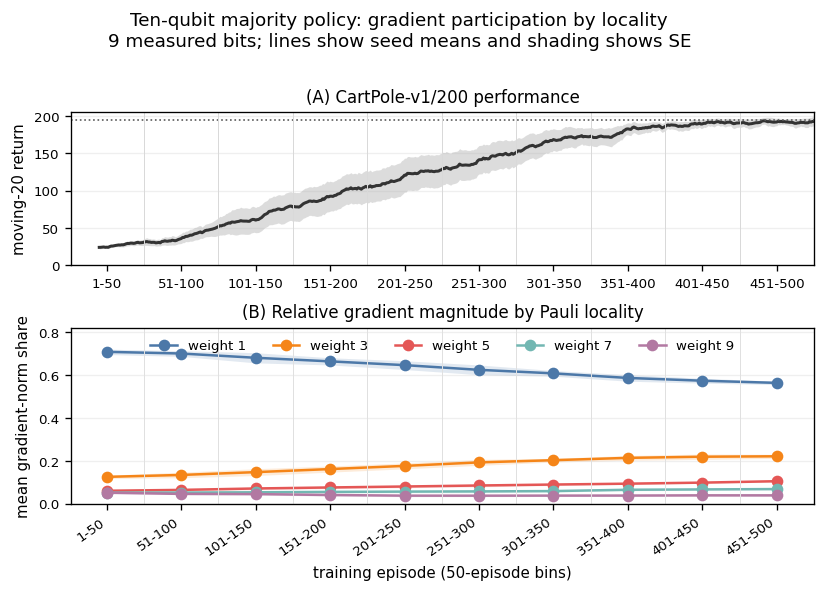

In [9]:
return_source = (
    episode_df.dropna(subset=["moving_20_return"])
    .groupby("episode", as_index=False)
    .agg(mean_moving20=("moving_20_return", "mean"),
         sem_moving20=("moving_20_return", lambda x: x.std(ddof=1) / math.sqrt(len(x))),
         n_seeds=("seed", "nunique"))
)
return_source.to_csv(RESULTS_DIR / "plot_return_source.csv", index=False)
bin_summary_df.to_csv(RESULTS_DIR / "plot_gradient_source.csv", index=False)
seed_bin_sector.to_csv(RESULTS_DIR / "plot_seed_values.csv", index=False)

colors = {1: "#4C78A8", 3: "#F58518", 5: "#E45756", 7: "#72B7B2", 9: "#B279A2"}
fig = plt.figure(figsize=(7.2, 4.8))
grid = fig.add_gridspec(2, 1, height_ratios=[1.0, 1.15], hspace=0.38)

ax_return = fig.add_subplot(grid[0, 0])
x = return_source.episode.to_numpy()
mean = return_source.mean_moving20.to_numpy()
sem = return_source.sem_moving20.to_numpy()
ax_return.plot(x, mean, color="#333333", linewidth=1.8)
ax_return.fill_between(x, np.clip(mean - sem, 0, 200), np.clip(mean + sem, 0, 200),
                       color="#777777", alpha=0.25, linewidth=0)
ax_return.axhline(195, color="0.35", linestyle=":", linewidth=1)
for boundary in range(50, 500, 50):
    ax_return.axvline(boundary, color="0.85", linewidth=0.6)
ax_return.set_xlim(1, 500)
ax_return.set_ylim(0, 205)
ax_return.set_ylabel("moving-20 return")
ax_return.set_title("(A) CartPole-v1/200 performance")
ax_return.grid(axis="y", alpha=0.2)

centers = np.arange(25, 501, 50)

ax_rms = fig.add_subplot(grid[1, 0], sharex=ax_return)
for weight in ODD_WEIGHTS:
    rows = bin_summary_df[bin_summary_df.weight == weight].sort_values("episode_bin")
    y = rows.nonnegative_norm_share_mean.to_numpy()
    yerr = rows.nonnegative_norm_share_sem.to_numpy()
    ax_rms.plot(centers, y, color=colors[weight], marker="o", linewidth=1.5,
                label=f"weight {weight}")
    ax_rms.fill_between(centers, np.maximum(y - yerr, 1e-12), y + yerr,
                        color=colors[weight], alpha=0.16, linewidth=0)
for boundary in range(50, 500, 50):
    ax_rms.axvline(boundary, color="0.88", linewidth=0.6)
ax_rms.set_ylabel("mean gradient-norm share")
ax_rms.set_xlabel("training episode (50-episode bins)")
ax_rms.set_xticks(centers, [f"{start}-{start+49}" for start in range(1, 500, 50)],
                  rotation=35, ha="right")
ax_rms.set_title("(B) Relative gradient magnitude by Pauli locality")
ax_rms.set_ylim(0, 0.82)
ax_rms.legend(ncol=5, frameon=False, loc="upper center")
ax_rms.grid(axis="y", alpha=0.2)

fig.suptitle(
    "Ten-qubit majority policy: gradient participation by locality\n"
    "9 measured bits; lines show seed means and shading shows SE",
    y=0.995, fontsize=11,
)
fig.subplots_adjust(top=0.82, bottom=0.14, left=0.12, right=0.98)
for suffix in ("png", "pdf"):
    fig.savefig(
        FIGURES_DIR / f"majority_gradient_norm_share_during_training_10q.{suffix}",
        dpi=300, bbox_inches="tight",
    )
plt.show()

## Scientific conclusion

For the ten-qubit circuit (nine measured bits), the higher-weight sectors become
**larger in nonnegative norm share** but **less aligned with the actual update**.
From episodes 1--50 to 451--500, the combined weights 3, 5, 7, and 9 rise from
approximately 0.292 to 0.436 of the summed coherent sector norms (paired change
0.145, 95% bootstrap CI [0.115, 0.172]).  Their combined signed alignment falls
from approximately 0.055 to -0.042 (change -0.097, CI [-0.161, -0.038]).

Thus the singleton sector remains the direction most aligned with the optimizer
gradient, while the higher-weight sector gradients grow in relative magnitude
and increasingly cancel or oppose one another.  Signed alignment and
nonnegative norm share answer different questions and must be reported
separately.

This experiment diagnoses the optimizer gradient of the **full majority
policy** along its own training trajectory.  It is not a counterfactual
local-only policy and not a classical-simulability test.  The next-bin
correlations are descriptive only and do not establish causality.

<a id="manifest"></a>
## Reproducibility manifest

The manifest records every durable output and its SHA-256 digest.  The
notebook verifies row counts, reconstruction tolerances, update coverage, and
the absence of missing seed/bin combinations before declaring completion.

In [10]:
import subprocess
import importlib.metadata as metadata

branch = subprocess.check_output(
    ["git", "branch", "--show-current"], cwd=ROOT, text=True
).strip()
commit = subprocess.check_output(
    ["git", "rev-parse", "HEAD"], cwd=ROOT, text=True
).strip()

config = {
    "environment_label": "CartPole-v1/200",
    "gymnasium_environment_id": "CartPole-v1",
    "trainer_side_step_cap": MAX_STEPS,
    "training_episodes": N_EPISODES,
    "batch_episodes": BATCH_EPISODES,
    "seeds": list(SEEDS),
    "architecture": SPEC,
    "training": TRAINING,
    "policy": "full deterministic binary majority",
    "measurement_effects": "Pi0=(I+M9)/2, Pi1=(I-M9)/2",
    "pauli_weights_present": list(ODD_WEIGHTS),
    "pauli_weights_absent": [2, 4, 6, 8],
    "freeze_choice": (
        "source solve threshold is recorded, but optimization continues through "
        "episode 500 so late gradients remain diagnostic"
    ),
    "attribution_scope": "quantum policy parameters only; exact coherent weight-sector VJPs",
    "per_string_incoherent_norms_reported": False,
    "n_jobs": N_JOBS,
    "protocol_version": PROTOCOL_VERSION,
}
(RESULTS_DIR / "experiment_config.json").write_text(json.dumps(config, indent=2))

software = {
    "python": sys.version,
    "platform": platform.platform(),
    "git_branch": branch,
    "git_commit": commit,
    "packages": {
        name: metadata.version(name)
        for name in (
            "qasp", "pennylane", "pennylane-lightning", "torch",
            "gymnasium", "numpy", "pandas", "scipy", "matplotlib",
            "joblib", "pyarrow",
        )
    },
}
(RESULTS_DIR / "software_metadata.json").write_text(json.dumps(software, indent=2))

files = []
for path in sorted(RESULTS_DIR.rglob("*")):
    if path.is_file() and path.name != "manifest.json":
        files.append({
            "path": str(path.relative_to(RESULTS_DIR)),
            "bytes": path.stat().st_size,
            "sha256": hashlib.sha256(path.read_bytes()).hexdigest(),
        })
manifest = {
    "completed": True,
    "n_seeds": len(SEEDS),
    "n_episodes": len(episode_df),
    "n_updates": len(update_df),
    "n_sector_rows": len(sector_df),
    "n_string_rows": 0,
    "max_reconstruction_relative_error_used": float(
        update_df.reconstruction_relative_error_used.max()
    ),
    "max_alignment_share_sum_error": float(
        update_df.alignment_share_sum_error.max()
    ),
    "all_cells_executed_from_clean_kernel": True,
    "protocol_version": PROTOCOL_VERSION,
    "scientific_conclusion": {
        "supports_blanket_late_higher_weight_prominence": False,
        "interpretation": (
            "Combined weights 3,5,7,9 increase from 0.292 to 0.436 in "
            "nonnegative coherent norm share, but their signed alignment "
            "falls from 0.055 to -0.042. Higher-weight magnitude and update "
            "alignment therefore move in opposite directions."
        ),
        "simulability_caveat": (
            "Gradient attribution does not establish equivalence to a local-only "
            "policy or increasing classical simulability."
        ),
        "association_caveat": (
            "Next-bin associations are descriptive and do not establish causality."
        ),
    },
    "files": files,
}
(RESULTS_DIR / "manifest.json").write_text(json.dumps(manifest, indent=2))

print("Branch:", branch, commit[:12])
print("Completed seeds:", len(metadata_df))
print("Total runtime hours:", metadata_df.runtime_seconds.sum() / 3600)
print("Max reconstruction error:", manifest["max_reconstruction_relative_error_used"])
print("Max alignment-sum error:", manifest["max_alignment_share_sum_error"])
print("Results:", RESULTS_DIR)

Branch: CO 4c36797973a8
Completed seeds: 10
Total runtime hours: 0.30058293490748234
Max reconstruction error: 4.587446255754912e-06
Max alignment-sum error: 1.0728836059570312e-06
Results: ./tests/results/majority_gradient_spectrum_during_training_10q
